#   Regression Metrics | MSE, MAE & RMSE | R2 Score & Adjusted R2 Score

In [2]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("placement (1).csv")

In [4]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [5]:
df.head()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   cgpa     200 non-null    float64
 1   package  200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [6]:
df.shape

(200, 2)

Text(0, 0.5, 'Package(in lpa)')

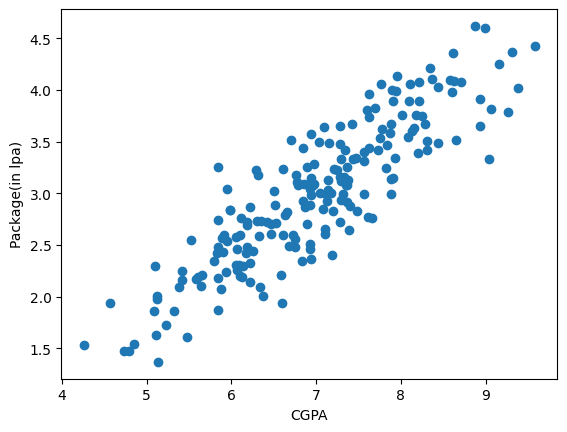

In [7]:

plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [8]:
x=df.iloc[:,0:1]
y=df.iloc[:,-1]

In [9]:
x

,cgpa
0,6.89
1,5.12
2,7.82
3,7.42
4,6.94
...,...
195,6.93
196,5.89
197,7.21
198,7.63


In [10]:
y

0      3.26
1      1.98
2      3.25
3      3.67
4      3.57
       ... 
195    2.46
196    2.57
197    3.24
198    3.96
199    2.33
Name: package, Length: 200, dtype: float64

In [11]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [12]:
from sklearn.linear_model import LinearRegression

In [13]:
lr=LinearRegression()

In [14]:
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
LinearRegression()

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Text(0, 0.5, 'Package(in lpa)')

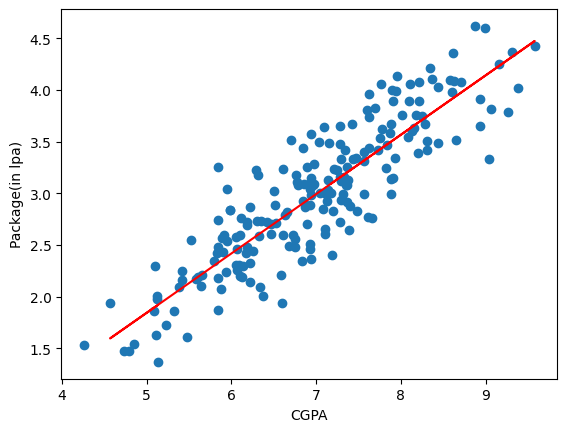

In [16]:
plt.scatter(df['cgpa'],df['package'])
plt.plot(x_train,lr.predict(x_train),color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [18]:
y_pred= lr.predict(x_test)

In [19]:
y_test

95     2.79
15     3.23
30     3.26
158    3.04
128    3.34
115    4.21
69     2.94
170    2.87
174    2.99
45     3.58
66     1.63
182    2.08
165    4.08
78     2.21
186    3.47
177    3.64
56     2.74
152    3.08
82     2.17
68     2.99
124    2.31
16     2.35
148    3.40
93     3.08
65     3.81
60     2.19
84     1.53
67     2.89
125    3.16
132    2.48
9      3.51
18     2.98
55     3.39
75     3.28
150    2.73
104    3.74
135    2.60
137    3.13
164    3.82
76     3.15
Name: package, dtype: float64

In [20]:
y_test.values

array([2.79, 3.23, 3.26, 3.04, 3.34, 4.21, 2.94, 2.87, 2.99, 3.58, 1.63,
       2.08, 4.08, 2.21, 3.47, 3.64, 2.74, 3.08, 2.17, 2.99, 2.31, 2.35,
       3.4 , 3.08, 3.81, 2.19, 1.53, 2.89, 3.16, 2.48, 3.51, 2.98, 3.39,
       3.28, 2.73, 3.74, 2.6 , 3.13, 3.82, 3.15])

In [21]:
print("MAE",mean_absolute_error(y_test,y_pred))

MAE 0.23150985393278373


In [22]:
print("MSE",mean_squared_error(y_test,y_pred))

MSE 0.08417638361329656


In [23]:
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))

RMSE 0.2901316659954521


In [24]:
print("MSE",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

MSE 0.7730984312051673


In [25]:

# Adjusted R2 score
x_test.shape

(40, 1)

In [26]:
1 - ((1-r2)*(40-1)/(40-1-1))

0.7671273372895138

# add random feature

In [27]:
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.871485,3.26
1,5.12,0.867875,1.98
2,7.82,0.286247,3.25
3,7.42,0.245447,3.67
4,6.94,0.789283,3.57


Text(0, 0.5, 'Package(in lpa)')

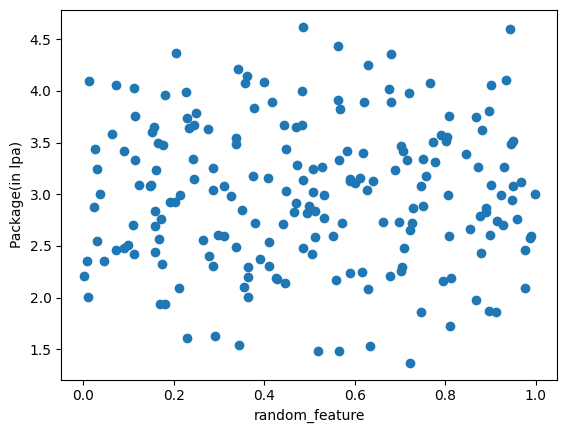

In [28]:

plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')

In [29]:

X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]

In [30]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)


In [31]:
lr = LinearRegression()

In [32]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [33]:

LinearRegression()

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
y_pred = lr.predict(X_test)

In [35]:

print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)


R2 score 0.7811263544024853


In [36]:

1 - ((1-r2)*(40-1)/(40-1-2))

0.7692953465323494

# add random featuer

In [37]:
new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]

In [38]:
new_df2.sample(5)


,cgpa,iq,package
91,6.22,2.94,2.14
175,7.04,2.30,3.50
182,5.88,0.88,2.08
68,7.56,3.19,2.99
104,7.62,2.74,3.74


Text(0, 0.5, 'Package(in lpa)')

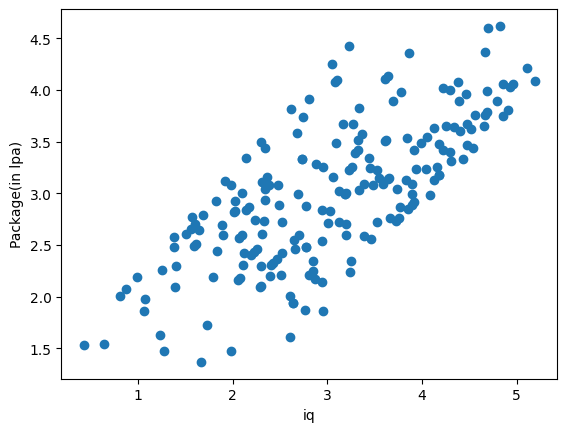

In [39]:

plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [40]:

np.random.randint(-100,100)

13

In [41]:

X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

In [42]:

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [43]:

lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)


In [44]:

print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.8408224197811477


In [45]:

1 - ((1-r2)*(40-1)/(40-1-2))



0.8322182262558043